In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dataset.csv")

print(df.head())

   atk_soft_attack  atk_hard_attack  atk_breakthrough  atk_org  atk_armor  \
0              761              129               152       70         42   
1              218              346               495       55        109   
2              700              209               435       38         23   
3              729              304               180       53        111   
4              347              175               230       39          1   

   atk_hardness  atk_supply  def_defense  def_soft_attack  def_hard_attack  \
0          0.34        0.55          919              537              241   
1          0.44        0.92          673              266              279   
2          0.08        0.70          453              182              203   
3          0.33        0.93          984              403              299   
4          0.48        0.83          933              453              109   

   def_org  def_piercing  def_entrenchment  def_supply  terrain_mod 

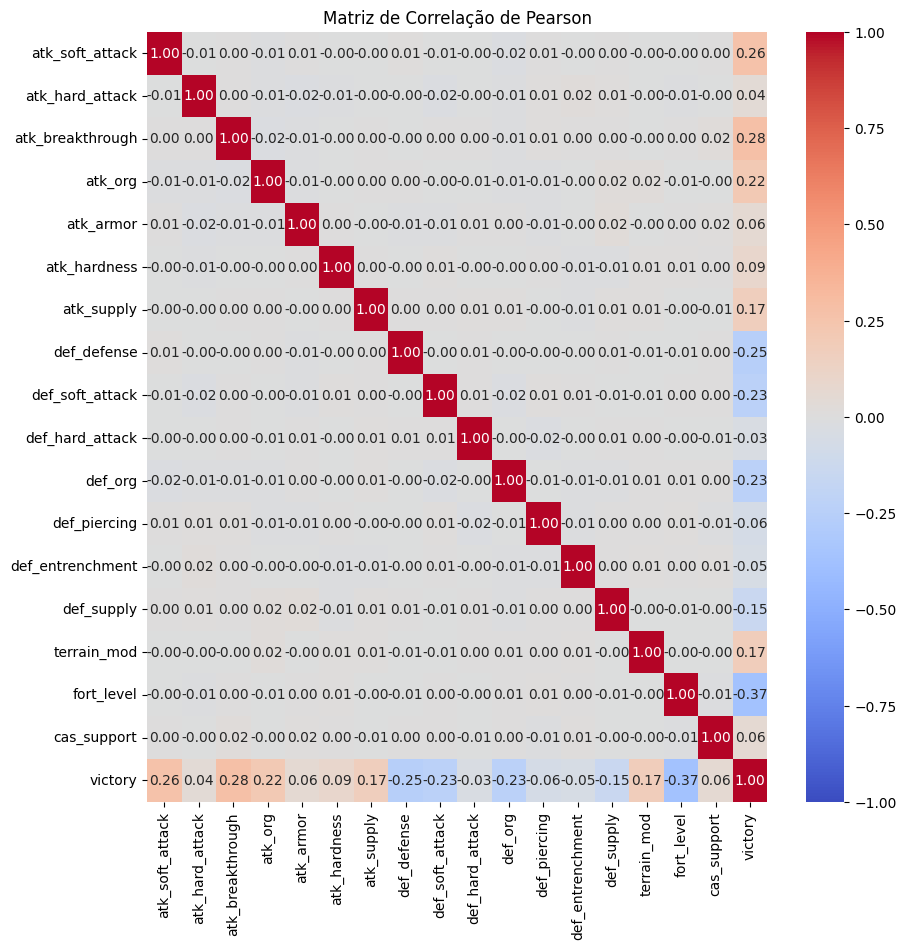

In [2]:
# matriz_corr = df.corr(method="pearson")
# print(matriz_corr)

plt.figure(figsize=(10, 10))
sns.heatmap(df.corr(method="pearson"), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlação de Pearson")
plt.show()

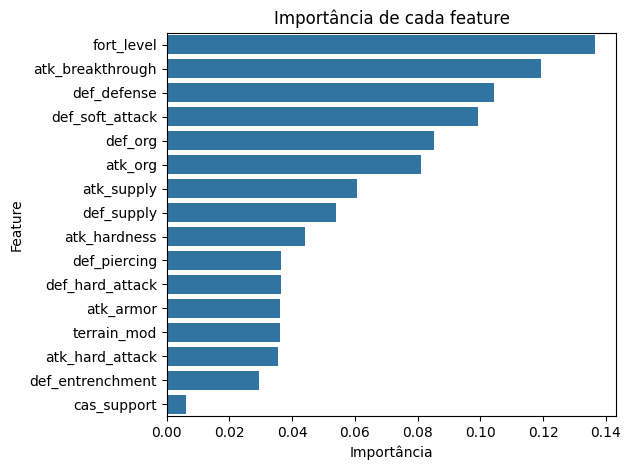

In [3]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Separando features (X) e variável-alvo (y)
X = df.iloc[:, 1:17].values
y = df.iloc[:, -1].values

# Guardando os nomes das features
feature_names = df.columns[1:17]

# Criando conjunto de treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42
)

# Treinando o modelo
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Calculando a importância de cada feature
importances = pd.Series(
    data=model.feature_importances_,
    index=feature_names
)

# Ordenando da mais importante para a menos importante
importances = importances.sort_values(ascending=False)

# Criando o gráfico
sns.barplot(x=importances.values, y=importances.index, orient="h")
plt.title("Importância de cada feature")
plt.xlabel("Importância")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [4]:

from sklearn.feature_selection import chi2, SelectKBest
import pandas as pd

# Separando features e variável-alvo
X = df.iloc[:, 1:17]
y = df.iloc[:, -1]

# Selecionando as 6 melhores features
seletor = SelectKBest(score_func=chi2, k=6)
X_selecionado = seletor.fit_transform(X, y)

# Mostrando os nomes das features selecionadas
features_selecionadas = X.columns[seletor.get_support()]

print("Features selecionadas:")
print(features_selecionadas.tolist())

# Mostrando as pontuações de todas as features
pontuacoes = pd.DataFrame({
    "Feature": X.columns,
    "Pontuação qui-quadrado": seletor.scores_
})

print(pontuacoes.sort_values(
    by="Pontuação qui-quadrado",
    ascending=False
))


Features selecionadas:
['atk_breakthrough', 'atk_org', 'def_defense', 'def_soft_attack', 'def_org', 'fort_level']
             Feature  Pontuação qui-quadrado
6        def_defense           117282.348058
1   atk_breakthrough            80263.773236
7    def_soft_attack            65365.422733
14        fort_level             8077.926297
9            def_org             3161.657314
2            atk_org             2728.001760
0    atk_hard_attack             1543.615555
10      def_piercing             1232.076679
3          atk_armor             1028.887430
8    def_hard_attack              728.199409
11  def_entrenchment              181.406352
15       cas_support               34.082088
13       terrain_mod               28.460493
5         atk_supply               26.167948
4       atk_hardness               20.602474
12        def_supply               19.956414


In [5]:

from sklearn.svm import LinearSVC
from sklearn.feature_selection import RFE
import pandas as pd

X = df.iloc[:, 1:17]
y = df.iloc[:, -1]

model = LinearSVC()
rfe = RFE(model, n_features_to_select=6, step=1).fit(X, y)

# Mostrar as features selecionadas
print("Features selecionadas:")
print(X.columns[rfe.support_].tolist())

# Mostrar o ranking de todas as features
ranking = pd.DataFrame({
    "Feature": X.columns,
    "Selecionada": rfe.support_,
    "Ranking": rfe.ranking_
})

print("\nRanking das features:")
print(ranking.sort_values("Ranking"))


Features selecionadas:
['atk_hardness', 'atk_supply', 'def_supply', 'terrain_mod', 'fort_level', 'cas_support']

Ranking das features:
             Feature  Selecionada  Ranking
5         atk_supply         True        1
4       atk_hardness         True        1
14        fort_level         True        1
15       cas_support         True        1
12        def_supply         True        1
13       terrain_mod         True        1
9            def_org        False        2
2            atk_org        False        3
11  def_entrenchment        False        4
1   atk_breakthrough        False        5
3          atk_armor        False        6
10      def_piercing        False        7
7    def_soft_attack        False        8
6        def_defense        False        9
8    def_hard_attack        False       10
0    atk_hard_attack        False       11
